In [1]:
import os
import cv2
import argparse
from ultralytics  import YOLO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from analyze_errors.matching import match_gt_with_results
from analyze_errors.metrics_calculate import compute_map, box_metrics_calculate, frame_level_metrics, compute_map_coco_style
from analyze_errors.visualization import visualize_prediction
from analyze_errors.eigen_cam import EigenCAM, visualize_prediction_with_cam, only_eigencam_visualizate

# === parameters ===
RANDOM_STATE = 42

In [2]:
# === parameters ===
path2data_file = "./data_v2.yaml"
split = "val"
path2model = "runs/detect/baseline_v0/overfitting_clahe/weights/best.pt"
imgsize = 512
project = "baseline_v0"
exp_name = "errors_analyze_overfitting_clahe"
conf = 0.001

nms_iou = 0.6
match_iou = 0.5

batch_size = 32

In [3]:
# === model init ===
model = YOLO(path2model)

In [4]:
results = model.predict(
    source="./dataset_v1/overfitting.txt",
    imgsz=imgsize,
    batch=batch_size,
    workers=2,
    seed=RANDOM_STATE,
    deterministic=True,
    conf=conf, # 0.0001 # низкий порог для честного расчёта mAP
    iou=nms_iou, # IoU для NMS при валидации
    verbose=False # Отключить печать
)

In [5]:
eigencam = EigenCAM(model, target_layer_idx=15)   # P5; для мелких объектов попробуй 15 (P3)

### mAP calculate

In [6]:
m = compute_map(results, "./dataset_yolo/labels", num_classes=1)
print(f"mAP0.5: {m['map_05']:0.4f}")
print(f"mAP0.5-0.95: {m['map_50_95']:.4f}")
print(m)

mAP0.5: 0.9802
mAP0.5-0.95: 0.5879
{'ap_table': array([[    0.98024,     0.98024,     0.98024,     0.94679,     0.84699,     0.62991,     0.33831,     0.14443,    0.032309,           0]]), 'map_05': 0.9802397851486332, 'map_50_95': 0.5879468561279744, 'per_iou_map': {0.5: 0.9802397851486332, 0.55: 0.9802397851486332, 0.6000000000000001: 0.9802397851486332, 0.6500000000000001: 0.9467880245814415, 0.7000000000000002: 0.8469930718513339, 0.7500000000000002: 0.6299125807343746, 0.8000000000000003: 0.338314429817182, 0.8500000000000003: 0.144431620852705, 0.9000000000000004: 0.0323094779968062, 0.9500000000000004: 0.0}, 'per_class_ap_05': {0: 0.9802397851486332}}


In [7]:
coco_m = compute_map_coco_style(results, "./dataset_yolo/labels", num_classes=1)
print(f"mAP0.5: {coco_m['map_05']}")
print(f"mAP0.5-0.95: {coco_m['map_50_95']}")
print(coco_m)

mAP0.5: 0.9836186170578003
mAP0.5-0.95: 0.5889605283737183
{'ap_table': array([[    0.98362,     0.98362,     0.98362,     0.94679,     0.84699,     0.62991,     0.33831,     0.14443,    0.032309,           0]], dtype=float32), 'map_05': 0.9836186170578003, 'map_50_95': 0.5889605283737183, 'per_iou_map': {0.5: 0.9836186170578003, 0.550000011920929: 0.9836186170578003, 0.6000000238418579: 0.9836186170578003, 0.6499999761581421: 0.9467880129814148, 0.699999988079071: 0.846993088722229, 0.75: 0.6299125552177429, 0.800000011920929: 0.3383144438266754, 0.8500000238418579: 0.14443162083625793, 0.8999999761581421: 0.03230947628617287, 0.949999988079071: 0.0}, 'per_class_ap_05': {0: 0.9836186170578003}, 'gt_count': array([65])}


In [8]:
frame_m = frame_level_metrics(results, "./dataset_yolo/labels")
for item in frame_m:
    print(f"{item}: {frame_m[item]:.4f}")

sensitivity: 1.0000
specificity: 1.0000
precision: 1.0000
recall: 1.0000
f1: 1.0000
accuracy: 1.0000
tp: 30.0000
fp: 0.0000
fn: 0.0000
tn: 30.0000


### TP, FP, FN, Precision, Recall for GT

In [9]:
boxes_metrics = []
for c in np.linspace(0.05, 0.9, 18):
    m = box_metrics_calculate(results, "./dataset_yolo/labels", iou=match_iou, conf=c)
    boxes_metrics.append({
        "conf": c,
        "iou": match_iou,
        "metrics": m 
    })

In [10]:
for item in boxes_metrics:
    ii = item['metrics']
    print(f"conf: {item['conf']:.2f}, | TP: {ii['TP']} | FP: {ii['FP']} | FN: {ii['FN']} | P: {ii['P']:.4f} R: {ii['R']:.4f} | F1: {ii['F1']:.4f}")

conf: 0.05, | TP: 64 | FP: 46 | FN: 1 | P: 0.5818 R: 0.9846 | F1: 0.7314
conf: 0.10, | TP: 64 | FP: 14 | FN: 1 | P: 0.8205 R: 0.9846 | F1: 0.8951
conf: 0.15, | TP: 63 | FP: 9 | FN: 2 | P: 0.8750 R: 0.9692 | F1: 0.9197
conf: 0.20, | TP: 61 | FP: 6 | FN: 4 | P: 0.9104 R: 0.9385 | F1: 0.9242
conf: 0.25, | TP: 60 | FP: 3 | FN: 5 | P: 0.9524 R: 0.9231 | F1: 0.9375
conf: 0.30, | TP: 60 | FP: 1 | FN: 5 | P: 0.9836 R: 0.9231 | F1: 0.9524
conf: 0.35, | TP: 60 | FP: 1 | FN: 5 | P: 0.9836 R: 0.9231 | F1: 0.9524
conf: 0.40, | TP: 58 | FP: 1 | FN: 7 | P: 0.9831 R: 0.8923 | F1: 0.9355
conf: 0.45, | TP: 58 | FP: 1 | FN: 7 | P: 0.9831 R: 0.8923 | F1: 0.9355
conf: 0.50, | TP: 56 | FP: 0 | FN: 9 | P: 1.0000 R: 0.8615 | F1: 0.9256
conf: 0.55, | TP: 52 | FP: 0 | FN: 13 | P: 1.0000 R: 0.8000 | F1: 0.8889
conf: 0.60, | TP: 49 | FP: 0 | FN: 16 | P: 1.0000 R: 0.7538 | F1: 0.8596
conf: 0.65, | TP: 46 | FP: 0 | FN: 19 | P: 1.0000 R: 0.7077 | F1: 0.8288
conf: 0.70, | TP: 44 | FP: 0 | FN: 21 | P: 1.0000 R: 0.6769

### Visualization

In [28]:
result_item = results[-3]
stem = result_item.path.split("\\")[-1].split('.')[0]
path2label = f"./dataset_yolo/labels/{stem}.txt"

# un_gt - idx для FN (из GT) - то есть можно сопоставить с теми, которые не были найдены
matches, un_gt, un_pred, gt = match_gt_with_results(
    result_item, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

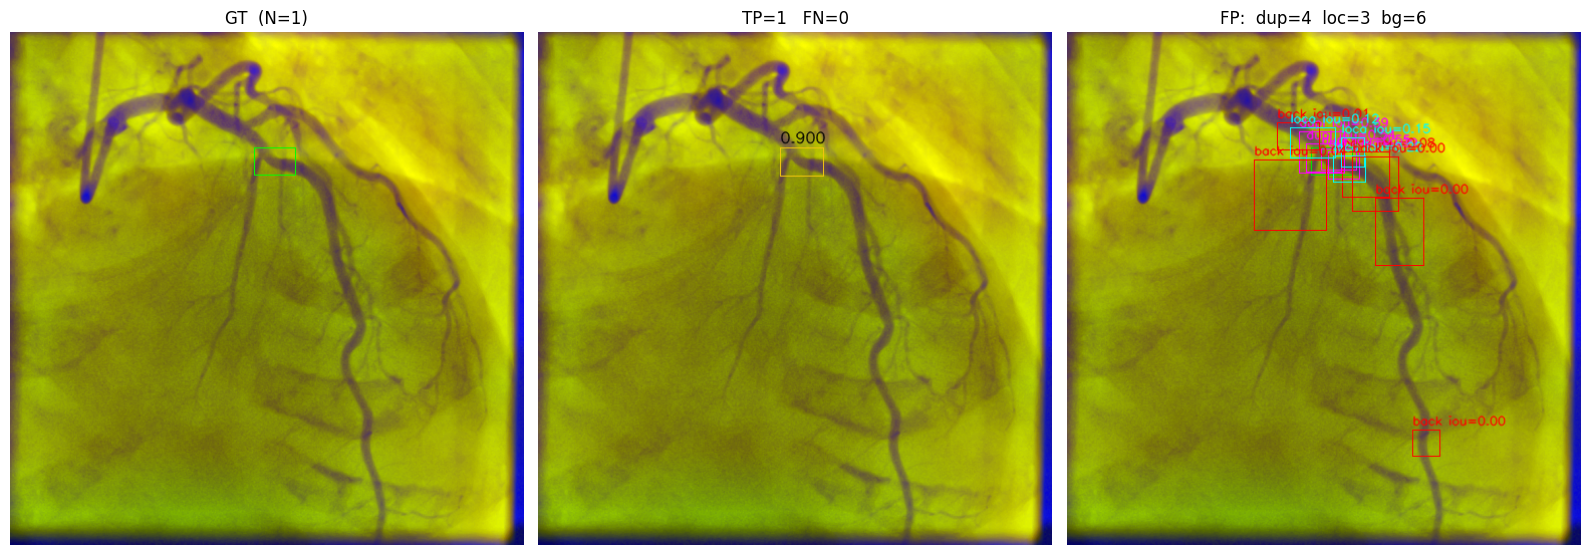

In [29]:
visualize_prediction(
    result_item, matches, un_gt, un_pred, gt
)

### EigenCAM visualization

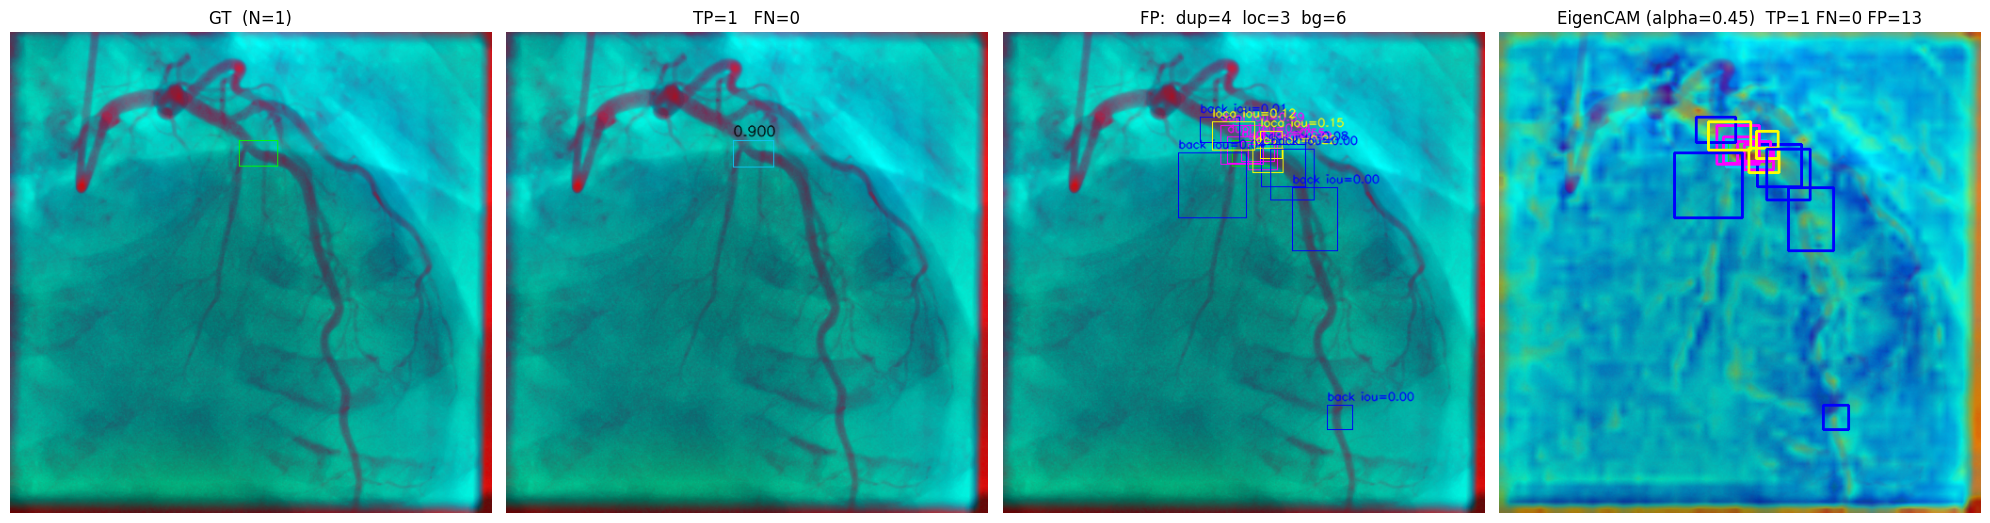

In [30]:
result_cam, heatmap, feat_shape = eigencam(result_item.path, imgsz=imgsize)

matches, un_gt, un_pred, gt = match_gt_with_results(
    result_cam, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

visualize_prediction_with_cam(result_cam, matches, un_gt, un_pred, gt, heatmap, alpha=0.45, figsize=(20, 15))

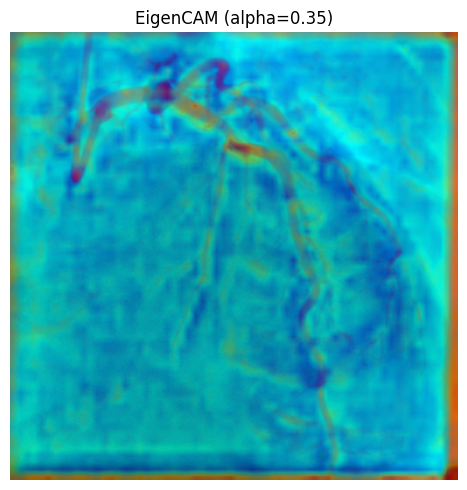

In [31]:
only_eigencam_visualizate(result_cam, heatmap, alpha=0.35, figsize=(9, 5))